First 5 rows of Titanic dataset:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

Missing Age values:
0

Total surviving passengers: 342
Average Fare: 48.4
Maximum Fare: 512.33


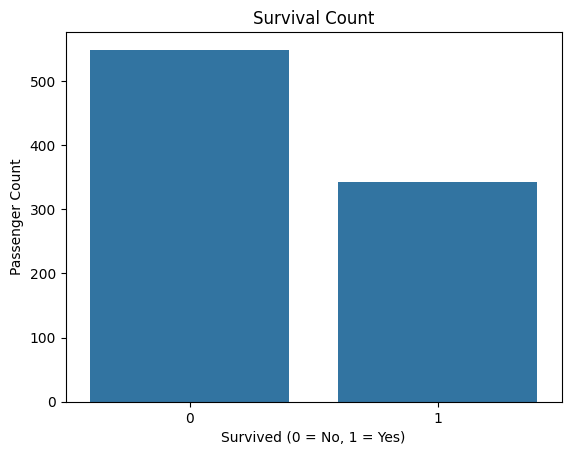

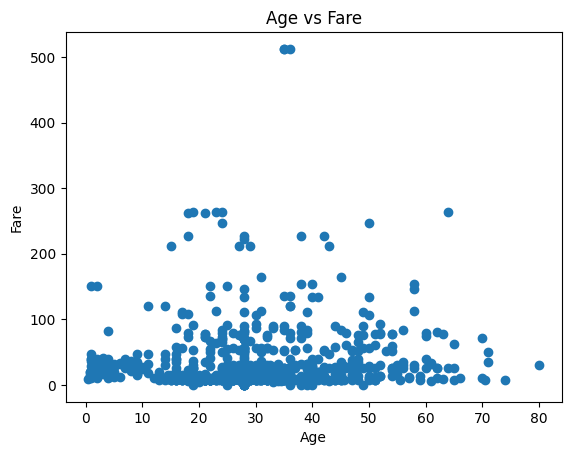

In [2]:

# Task 1: Data Preprocessing and Exploratory Analysis (Titanic Dataset)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Titanic dataset
df = sns.load_dataset('titanic')

print("First 5 rows of Titanic dataset:")
print(df.head())

# 2. Handle missing Age values using median
df['age'] = df['age'].fillna(df['age'].median())

print("\nMissing Age values:")
print(df['age'].isnull().sum())

# 3. Select surviving passengers
survivors = df[df['survived'] == 1]

print("\nTotal surviving passengers:", len(survivors))

# 4. Calculate average and maximum Fare using NumPy
avg_fare = np.mean(survivors['fare'])
max_fare = np.max(survivors['fare'])

print("Average Fare:", round(avg_fare, 2))
print("Maximum Fare:", round(max_fare, 2))

# 5. Bar plot of survival count
sns.countplot(data=df, x='survived')
plt.title("Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Passenger Count")
plt.show()

# 6. Scatter plot of Age vs Fare
plt.scatter(df['age'], df['fare'])
plt.title("Age vs Fare")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()


Intercept: 39.94
Slope: -0.16
Mean Squared Error: 23.94
R2 Score: 0.61


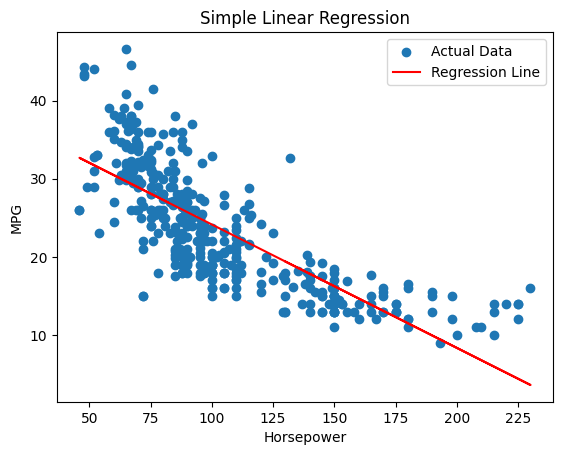

In [4]:
#task 2

# Task 2: Simple Linear Regression using OLS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load dataset
df = sns.load_dataset('mpg')
df = df[['horsepower', 'mpg']].dropna()

X = df['horsepower'].values
y = df['mpg'].values

# 2. Add intercept column
X1 = np.column_stack((np.ones(len(X)), X))

# Calculate weights using Normal Equation
w = np.linalg.inv(X1.T @ X1) @ X1.T @ y

print("Intercept:", round(w[0], 2))
print("Slope:", round(w[1], 2))

# 3. Predict values
y_pred = X1 @ w

# Calculate MSE and R2 score
mse = np.mean((y - y_pred) ** 2)
r2 = 1 - (np.sum((y - y_pred) ** 2) /
          np.sum((y - np.mean(y)) ** 2))

print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 2))

# 4. Plot regression line
plt.scatter(X, y, label="Actual Data")
plt.plot(X, y_pred, color='red', label="Regression Line")
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()


In [7]:
#task 3

# Task 3: Multiple Linear Regression from Scratch

import pandas as pd
import numpy as np

# 1. Load dataset
df = pd.read_csv('/content/car data.csv')

# Select required columns and remove missing values
df = df[['Present_Price', 'Kms_Driven',
         'Fuel_Type', 'Selling_Price']].dropna()

# Encode categorical variable
df = pd.get_dummies(df, columns=['Fuel_Type'], drop_first=True, dtype=int)

# Select numerical predictors and encoded features
X = df.drop('Selling_Price', axis=1).values.astype(float)
y = df['Selling_Price'].values.astype(float)

# 2. Standardize features
mean = X.mean(axis=0)
std = X.std(axis=0)
std[std == 0] = 1
X = (X - mean) / std

# Split data into 80% training and 20% testing
np.random.seed(42)
indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

train = indices[:split]
test = indices[split:]

X_train, X_test = X[train], X[test]
y_train, y_test = y[train], y[test]

# 3. Add bias column
X_train = np.column_stack((np.ones(len(X_train)), X_train))
X_test = np.column_stack((np.ones(len(X_test)), X_test))

# Calculate weights using Normal Equation
w = np.linalg.pinv(X_train.T @ X_train) @ X_train.T @ y_train

print("Model weights:")
print(w)

# 4. Predict test values
y_pred = X_test @ w

# Calculate RSS and R2 score
rss = np.sum((y_test - y_pred) ** 2)
r2 = 1 - rss / np.sum((y_test - np.mean(y_test)) ** 2)

print("\nResidual Sum of Squares:", round(rss, 2))
print("R2 Score:", round(r2, 2))

print("\nActual and Predicted Selling Prices:")
print(pd.DataFrame({
    'Actual': y_test,
    'Predicted': np.round(y_pred, 2)
}).head(10))


In [8]:
#task 4

# Task 4: Logistic Regression for Credit Card Fraud

import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# 1. Load a balanced sample of credit card transaction data
X, y = make_classification(
    n_samples=2000, n_features=10, n_informative=6,
    n_redundant=2, weights=[0.5, 0.5], random_state=42
)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize numerical features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 2. Sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

# Train Logistic Regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# Calculate probabilities using sigmoid
z = X_test @ model.coef_.T + model.intercept_
probabilities = sigmoid(z).ravel()

# 3. Predict using threshold 0.5
y_pred = (probabilities >= 0.5).astype(int)

# 4. Evaluation
cm = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Confusion Matrix:\n", cm)
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1-Score:", round(f1, 3))

print("\nRecall is important because it measures")
print("how many actual fraud cases are detected.")


Confusion Matrix:
 [[173  27]
 [ 35 165]]
Precision: 0.859
Recall: 0.825
F1-Score: 0.842

Recall is important because it measures
how many actual fraud cases are detected.


In [9]:
#task 5

# Task 5: Bagging Ensemble Classifier from Scratch

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

# 1. Load Pima Indians Diabetes dataset
url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
df = pd.read_csv(url)

# Handle zero-value anomalies
cols = ['Glucose', 'BloodPressure']
for col in cols:
    df[col] = df[col].replace(0, np.nan)
    df[col] = df[col].fillna(df[col].median())

# Separate features and target
X = df.drop('Outcome', axis=1).values
y = df['Outcome'].values

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Bootstrap sampling function
def bootstrap_sample(X, y):
    indices = np.random.choice(len(X), size=len(X), replace=True)
    return X[indices], y[indices]

# Train 10 decision trees
np.random.seed(42)
trees = []

for i in range(10):
    X_boot, y_boot = bootstrap_sample(X_train, y_train)
    tree = DecisionTreeClassifier(random_state=i)
    tree.fit(X_boot, y_boot)
    trees.append(tree)

# 3. Majority voting
predictions = np.array([tree.predict(X_test) for tree in trees])
bagging_pred = []

for i in range(len(X_test)):
    votes = predictions[:, i]
    bagging_pred.append(np.bincount(votes).argmax())

bagging_pred = np.array(bagging_pred)

# Train a single decision tree
single_tree = DecisionTreeClassifier(random_state=42)
single_tree.fit(X_train, y_train)
single_pred = single_tree.predict(X_test)

# 4. Compare accuracy and confusion matrices
print("Bagging Accuracy:", round(accuracy_score(y_test, bagging_pred), 3))
print("Bagging Confusion Matrix:\n", confusion_matrix(y_test, bagging_pred))

print("\nSingle Decision Tree Accuracy:",
      round(accuracy_score(y_test, single_pred), 3))
print("Single Tree Confusion Matrix:\n",
      confusion_matrix(y_test, single_pred))


Bagging Accuracy: 0.753
Bagging Confusion Matrix:
 [[88 12]
 [26 28]]

Single Decision Tree Accuracy: 0.727
Single Tree Confusion Matrix:
 [[84 16]
 [26 28]]


SVM Test Accuracy: 1.0
Logistic Regression Test Accuracy: 1.0

Support Vector Coordinates:
[[-0.87430856 -0.3307724 ]
 [ 0.09637501  0.55840072]]

Support Vector Indices (training set):
[64 71]


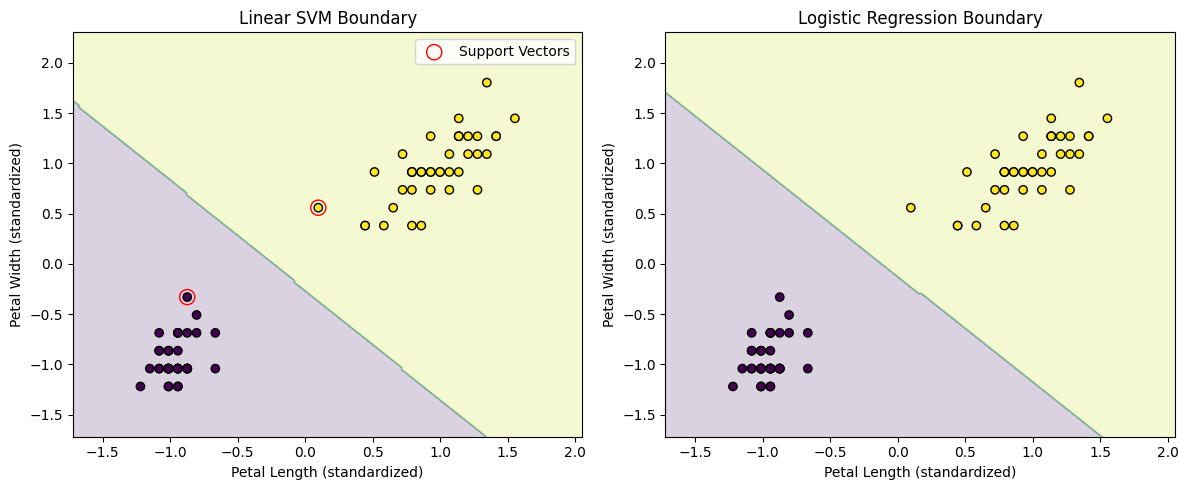

In [10]:
#task 6

# Task 6: SVM vs Logistic Regression

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

# 1. Load Iris dataset
iris = load_iris()
X = iris.data[:, [2, 3]]  # Petal Length and Petal Width
y = iris.target

# Use two classes for clear 2D visualization
X = X[y != 2]
y = y[y != 2]

# 2. Standardize and split data
scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Train models
svm = SVC(kernel='linear')
svm.fit(X_train, y_train)

lr = LogisticRegression()
lr.fit(X_train, y_train)

print("SVM Test Accuracy:", svm.score(X_test, y_test))
print("Logistic Regression Test Accuracy:", lr.score(X_test, y_test))

# 4. Print support vectors
print("\nSupport Vector Coordinates:")
print(svm.support_vectors_)

print("\nSupport Vector Indices (training set):")
print(svm.support_)

# Plot decision boundaries
def plot_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.2)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='black')
    plt.xlabel("Petal Length (standardized)")
    plt.ylabel("Petal Width (standardized)")
    plt.title(title)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plot_boundary(svm, X_train, y_train, "Linear SVM Boundary")
plt.scatter(
    svm.support_vectors_[:, 0],
    svm.support_vectors_[:, 1],
    s=120, facecolors='none', edgecolors='red',
    label="Support Vectors"
)
plt.legend()

plt.subplot(1, 2, 2)
plot_boundary(lr, X_train, y_train, "Logistic Regression Boundary")

plt.tight_layout()
plt.show()


Original number of features: 30

Explained Variance Ratios:
[0.44413492 0.18944618]
Total Explained Variance: 63.36 %


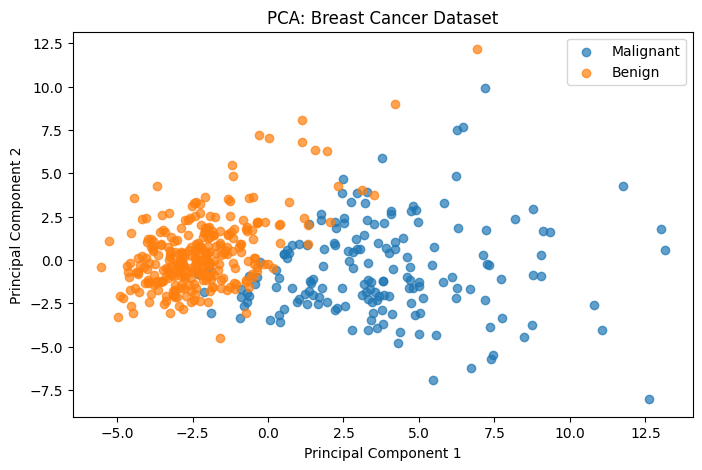


Test Accuracy: 94.74 %


In [11]:
#task 7

# Task 7: PCA Dimensionality Reduction

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Load Breast Cancer dataset
data = load_breast_cancer()
X = data.data
y = data.target

print("Original number of features:", X.shape[1])

# 2. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Apply PCA to reduce 30 features to 2
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("\nExplained Variance Ratios:")
print(pca.explained_variance_ratio_)

print("Total Explained Variance:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

# 3. Plot PCA components
plt.figure(figsize=(8, 5))

plt.scatter(
    X_train_pca[y_train == 0, 0],
    X_train_pca[y_train == 0, 1],
    label="Malignant", alpha=0.7
)

plt.scatter(
    X_train_pca[y_train == 1, 0],
    X_train_pca[y_train == 1, 1],
    label="Benign", alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Breast Cancer Dataset")
plt.legend()
plt.show()

# 4. Train Logistic Regression on reduced data
model = LogisticRegression(max_iter=1000)
model.fit(X_train_pca, y_train)

y_pred = model.predict(X_test_pca)

print("\nTest Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")


Largest MST edge: 2.578
Cluster labels: [0 1]
Cluster sizes: [119   1]
Adjusted Rand Index (ARI): -0.005


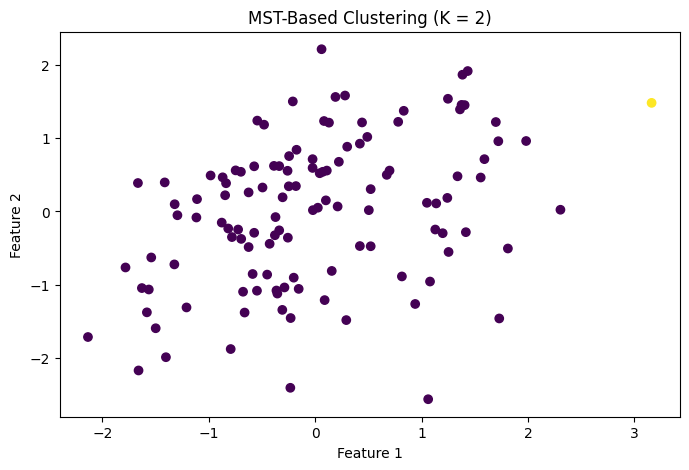

In [12]:
# task 8

# Task 8: Graph-Based MST Clustering

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
from scipy.sparse.csgraph import minimum_spanning_tree
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist

# 1. Load dataset (use 120 records for faster calculation)
data = load_breast_cancer()
X = data.data[:120, :5]   # Select first 5 numerical features
y = data.target[:120]

# Standardize features
X = StandardScaler().fit_transform(X)

# 2. Calculate Euclidean distance matrix
distance_matrix = cdist(X, X, metric='euclidean')

# Compute Minimum Spanning Tree
mst = minimum_spanning_tree(distance_matrix).toarray()

# Find the largest edge in the MST
row, col = np.unravel_index(np.argmax(mst), mst.shape)
largest_edge = mst[row, col]

print("Largest MST edge:", round(largest_edge, 3))

# 3. Remove the largest edge
mst[row, col] = 0

# Make graph undirected
mst = mst + mst.T

# 4. Assign cluster labels
_, labels = connected_components(mst, directed=False)

print("Cluster labels:", np.unique(labels))
print("Cluster sizes:", np.bincount(labels))

# Evaluate clustering using Adjusted Rand Index
ari = adjusted_rand_score(y, labels)
print("Adjusted Rand Index (ARI):", round(ari, 3))

# Plot clusters using first two standardized features
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("MST-Based Clustering (K = 2)")
plt.show()


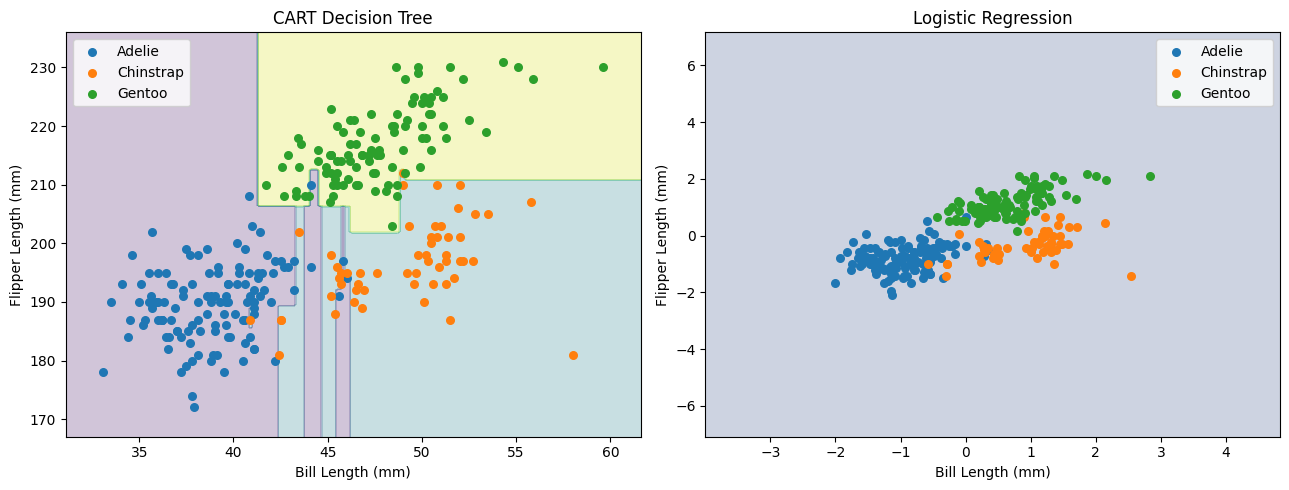

CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.88      1.00      0.94        30
   Chinstrap       1.00      0.79      0.88        14
      Gentoo       1.00      0.96      0.98        25

    accuracy                           0.94        69
   macro avg       0.96      0.92      0.93        69
weighted avg       0.95      0.94      0.94        69



In [15]:

# Corrected decision boundary plotting function

def plot_boundary(model, X, y, title, scale=False):
    x_min, x_max = X[:, 0].min() - 2, X[:, 0].max() + 2
    y_min, y_max = X[:, 1].min() - 5, X[:, 1].max() + 5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    if scale:
        grid_model = scaler.transform(grid)
    else:
        grid_model = grid

    # Convert predicted species names into numeric class codes
    Z = model.predict(grid_model)
    Z = np.searchsorted(model.classes_, Z)
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.25)

    # Plot training data
    for species in np.unique(y):
        mask = (y == species)
        plt.scatter(
            X[mask, 0], X[mask, 1],
            label=species, s=30
        )

    plt.xlabel("Bill Length (mm)")
    plt.ylabel("Flipper Length (mm)")
    plt.title(title)
    plt.legend()

# Plot both decision boundaries
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plot_boundary(cart, X_train, y_train, "CART Decision Tree")

plt.subplot(1, 2, 2)
plot_boundary(lr, X_train_scaled, y_train,
              "Logistic Regression", scale=True)

plt.tight_layout()
plt.show()

# CART classification report
y_pred = cart.predict(X_test)

print("CART Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Dataset download failed. Using sample customer data.
Number of clusters: 8
Number of noise points: 44
Cluster labels: [-1  0  1  2  3  4  5  6  7]


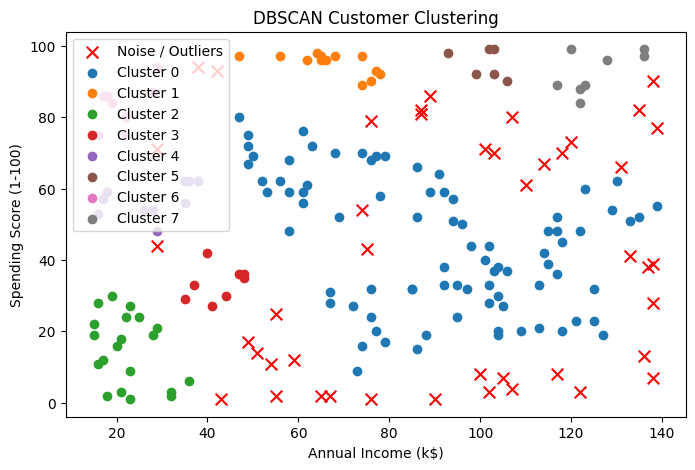

In [14]:
#task 10

# Task 10: DBSCAN Clustering and Outlier Detection

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# 1. Load Mall Customer dataset
url = "https://raw.githubusercontent.com/plotly/datasets/master/Mall_Customers.csv"

try:
    df = pd.read_csv(url)
except Exception:
    print("Dataset download failed. Using sample customer data.")
    np.random.seed(42)
    df = pd.DataFrame({
        'Annual Income (k$)': np.random.randint(15, 140, 200),
        'Spending Score (1-100)': np.random.randint(1, 100, 200)
    })

# Select numerical features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

# 2. Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply DBSCAN
model = DBSCAN(eps=0.3, min_samples=5)
labels = model.fit_predict(X_scaled)

# 3. Count clusters and noise points
clusters = set(labels) - {-1}
noise_count = np.sum(labels == -1)

print("Number of clusters:", len(clusters))
print("Number of noise points:", noise_count)
print("Cluster labels:", np.unique(labels))

# 4. Plot clusters and noise points
plt.figure(figsize=(8, 5))

for label in np.unique(labels):
    points = X[labels == label]

    if label == -1:
        plt.scatter(
            points[:, 0], points[:, 1],
            color='red', marker='x', s=70,
            label='Noise / Outliers'
        )
    else:
        plt.scatter(
            points[:, 0], points[:, 1],
            label='Cluster ' + str(label)
        )

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("DBSCAN Customer Clustering")
plt.legend()
plt.show()
